# von Mises vs Normal on the circle, and unwrap's link functions

Reproduces the two link-function figures from the supplement of the *unwrap*
paper (jgraving/circstats). Both cells are self-contained (numpy / scipy /
matplotlib only - no fits, no unwrap import), fully deterministic, and write
their PDFs into `figures/` next to the notebook.

- `figures/vonmises_gaussian.pdf` - polar plots comparing a wrapped von Mises
  density with an unbounded Normal (identity-treatment) density for a ladder
  of concentrations kappa, at mean direction 0 (top row) and at -pi (bottom
  row). The Normal density never wraps, so its mass spills outside the unit
  circle at -pi - the geometry a linear treatment of the response assumes.
- `figures/link-functions-and-gradients.pdf` - the mean-direction links
  (2arctan, atan2, circular-modulo) and the concentration links (exp,
  softplus, rectifier), each with its derivative. The circular-modulo and
  2arctan rows show the discontinuities of the bounded/periodic treatments
  that the periwinkles rotation example (periwinkles_rotation_example.ipynb)
  exploits.

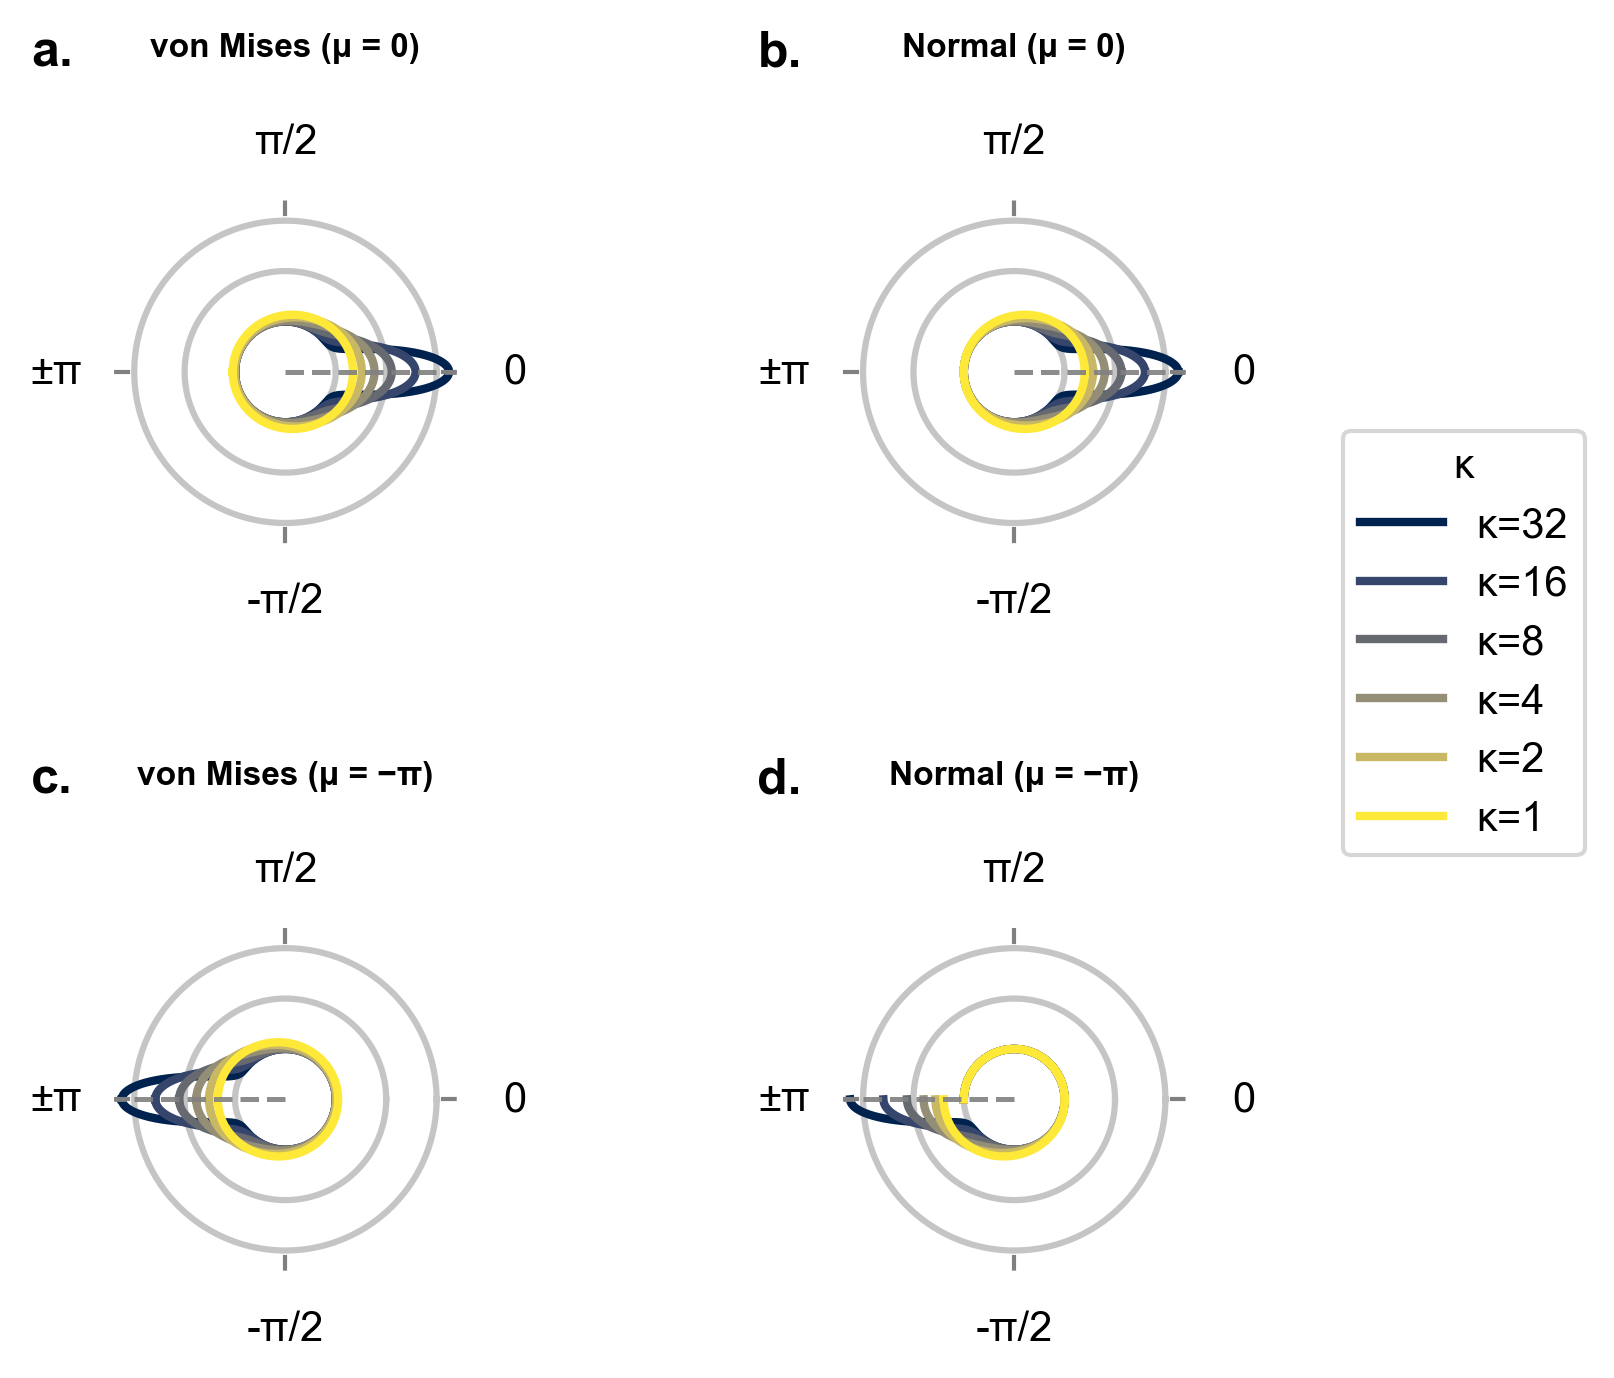

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi, sqrt
from pathlib import Path
from scipy.special import i0 as bessel_i0

# ---- global style (Arial + transparent backgrounds) ----
plt.rcParams.update({
    "font.family": "Arial",
    # Make mathtext look Arial-ish too
    "mathtext.fontset": "custom",
    "mathtext.rm": "Arial",
    "mathtext.it": "Arial:italic",
    "mathtext.bf": "Arial:bold",
})

# ---- parameters ----
kappas = np.array([1.0, 2.0, 4.0, 8.0, 16.0, 32.0])[::-1]
colors = plt.cm.cividis(np.linspace(0, 1, len(kappas)))
theta = np.linspace(-np.pi, np.pi, 3000)  # master angle grid
panel_labels = ["a.", "b.", "c.", "d."]

def style_polar(ax, title, mu):
    ax.set_title(title, pad=16, fontsize=8, weight="bold")
    ax.grid(False)
    ax.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2])
    ax.set_xticklabels(["0", "π/2", "±π", "-π/2"])
    ax.set_yticks([])
    ax.set_ylim(0, 3.4)
    ax.spines['polar'].set_visible(False)   # hide outer frame

    # transparent subplot (axes) background
    ax.set_facecolor("none")
    ax.patch.set_facecolor("none")
    ax.patch.set_alpha(0)

    # reference circles at r=1, r=2, and r=3
    t_ref = np.linspace(0, 2*np.pi, 721)
    ax.plot(t_ref, np.ones_like(t_ref), color="gray", linewidth=1.5, alpha=0.45, zorder=0)       # r=1
    ax.plot(t_ref, np.ones_like(t_ref) + 1, color="gray", linewidth=1.5, alpha=0.45, zorder=0)   # r=2
    ax.plot(t_ref, np.ones_like(t_ref) + 2, color="gray", linewidth=1.5, alpha=0.45, zorder=0)   # r=3

    # mean direction line
    rmax = ax.get_ylim()[1]
    ax.plot([mu, mu], [0, rmax], linestyle="--", linewidth=1.2, color="gray", alpha=0.9)

    # short tick marks at 4 angles
    tick_len = 0.08 * rmax
    for a in [0, np.pi/2, np.pi, 3*np.pi/2]:
        ax.plot([a, a], [rmax - tick_len, rmax], color="gray", linewidth=1)

def von_mises_pdf(theta, mu, kappa):
    return np.exp(kappa*np.cos(theta - mu)) / (2*np.pi*bessel_i0(kappa))

def gaussian_pdf_on_angle(theta, mu, kappa):
    sigma = 1/np.sqrt(kappa)  # match curvature of von Mises at the mode
    return (1/(sigma*np.sqrt(2*np.pi))) * np.exp(-0.5*((theta - mu)/sigma)**2)

def plot_von_mises(ax, mu):
    for kappa, color in zip(kappas, colors):
        r = von_mises_pdf(theta, mu, kappa)
        ax.plot(theta, r + 1.0, color=color, linewidth=2, label=f"κ={kappa:g}")

def plot_gaussian_nonwrapping(ax, mu):
    split_idx = np.searchsorted(theta, 0.0)
    for kappa, color in zip(kappas, colors):
        r = gaussian_pdf_on_angle(theta, mu, kappa) + 1.0
        ax.plot(theta[:split_idx], r[:split_idx], color=color, linewidth=2, label=f"κ={kappa:g}")
        ax.plot(theta[split_idx:], r[split_idx:], color=color, linewidth=2)

# ---- figure ----
fig = plt.figure(figsize=(5, 5), dpi=300)

# transparent figure background
fig.patch.set_facecolor("none")
fig.patch.set_alpha(0)

ax_vm_top  = fig.add_subplot(2, 2, 1, projection='polar')
ax_g_top   = fig.add_subplot(2, 2, 2, projection='polar')
ax_vm_bot  = fig.add_subplot(2, 2, 3, projection='polar')
ax_g_bot   = fig.add_subplot(2, 2, 4, projection='polar')
axes = [ax_vm_top, ax_g_top, ax_vm_bot, ax_g_bot]

# ---- top row: μ = 0 ----
mu_top = 0.0
plot_von_mises(ax_vm_top, mu_top)
plot_gaussian_nonwrapping(ax_g_top, mu_top)
style_polar(ax_vm_top, "von Mises (μ = 0)", mu_top)
style_polar(ax_g_top,  "Normal (μ = 0)",  mu_top)

# ---- bottom row: μ = −π ----
mu_bot = -np.pi
plot_von_mises(ax_vm_bot, mu_bot)
plot_gaussian_nonwrapping(ax_g_bot, mu_bot)
style_polar(ax_vm_bot, "von Mises (μ = −π)", mu_bot)
style_polar(ax_g_bot,  "Normal (μ = −π)",  mu_bot)

# ---- add panel labels ----
for ax, label in zip(axes, panel_labels):
    ax.text(-0.12, 1.5, label, transform=ax.transAxes,
            fontsize=12, fontweight="bold", va="top", ha="right")

# ---- one shared legend on the right, closer ----
handles, labels = ax_vm_top.get_legend_handles_labels()
leg = fig.legend(handles, labels, title="κ", frameon=True,
                 loc="center left", bbox_to_anchor=(0.96, 0.5))

# make legend background transparent (keep border)
leg.get_frame().set_facecolor("none")

fig.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig("./figures/vonmises_gaussian.pdf", bbox_inches="tight", transparent=True)

plt.show()

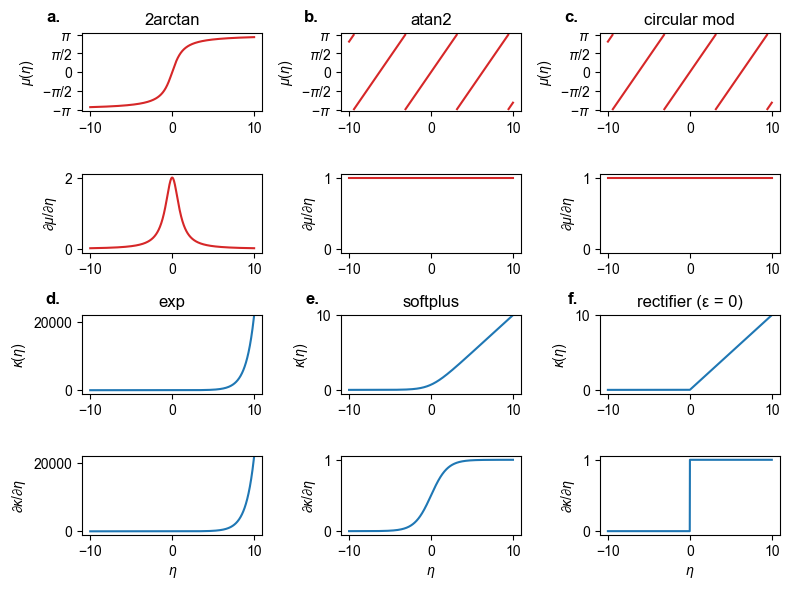

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---- global style (Arial + consistent mathtext) ----
plt.rcParams.update({
    "font.family": "Arial",
    "mathtext.fontset": "custom",
    "mathtext.rm": "Arial",
    "mathtext.it": "Arial:italic",
    "mathtext.bf": "Arial:bold",
})

PI = np.pi
EPS = np.finfo(float).eps

# Define functions and gradients
def softplus(eta): return np.log1p(np.exp(eta))
def grad_softplus(eta): return 1 / (1 + np.exp(-eta))
def rectifier(eta): return np.maximum(EPS, eta)
def grad_rectifier(eta): return (eta > EPS).astype(float)
def atan2_fn(eta): return np.arctan2(np.sin(eta), np.cos(eta))
def grad_atan2_fn(eta):
    grad = np.ones_like(eta)
    wrap_points = np.isclose((eta + PI) % (2 * PI), 0, atol=1e-3)
    grad[wrap_points] = np.nan
    return grad
def circular_modulo(eta): return ((eta + PI) % (2 * PI)) - PI
def grad_circular_modulo(eta):
    grad = np.ones_like(eta)
    wrap_points = np.isclose((eta + PI) % (2 * PI), 0, atol=1e-3)
    grad[wrap_points] = np.nan
    return grad
def two_arctan(eta): return 2 * np.arctan(eta)
def grad_two_arctan(eta): return 2 / (1 + eta**2)
def exp_fn(eta): return np.exp(eta)
def grad_exp_fn(eta): return np.exp(eta)

# --- helper: break lines at discontinuities (prevents vertical wrap lines)
def plot_with_breaks(ax, x, y, threshold=np.pi, **kwargs):
    y_plot = y.copy()
    jumps = np.where(np.abs(np.diff(y)) > threshold)[0]
    # insert NaN right AFTER the jump so the segment breaks
    y_plot[jumps + 1] = np.nan
    ax.plot(x, y_plot, **kwargs)

# Plotting range
eta_range = np.linspace(-10, 10, 1000)

# Set up subplots
fig, axes = plt.subplots(4, 3, figsize=(8, 6))
plt.subplots_adjust(hspace=0.6)

# ---- transparent figure + axes backgrounds ----
fig.patch.set_facecolor("none")
fig.patch.set_alpha(0)
for ax in axes.ravel():
    ax.set_facecolor("none")
    ax.patch.set_facecolor("none")
    ax.patch.set_alpha(0)

# Mean direction links
mean_links = [
    ("2arctan", two_arctan, grad_two_arctan, [-PI - 0.05 * PI, PI + 0.05 * PI], [-0.1, 2.1]),
    ("atan2", atan2_fn, grad_atan2_fn, [-PI - 0.05 * PI, PI + 0.05 * PI], [-0.05, 1.05]),
    ("circular mod", circular_modulo, grad_circular_modulo, [-PI - 0.05 * PI, PI + 0.05 * PI], [-0.05, 1.05]),
]

# Concentration links
kappa_links = [
    ("exp", exp_fn, grad_exp_fn, [-1000, np.exp(10)], [-1000, np.exp(10)]),
    ("softplus", softplus, grad_softplus, [-0.5, 10], [-0.05, 1.05]),
    ("rectifier (ε = 0)", rectifier, grad_rectifier, [-0.5, 10], [-0.05, 1.05]),
]

# Panel labels for function plots only
panel_labels = ["a.", "b.", "c.", "d.", "e.", "f."]

# Plot mean links
for i, (name, func, grad, ylims_func, ylims_grad) in enumerate(mean_links):
    ax_f = axes[0, i]
    y = func(eta_range)
    if name in ("atan2", "circular mod"):
        plot_with_breaks(ax_f, eta_range, y, threshold=np.pi, color="tab:red")
    else:
        ax_f.plot(eta_range, y, color="tab:red")
    ax_f.set_title(name)
    ax_f.set_ylabel(r"$\mu(\eta)$")

    # y-axis in radians: ticks from -pi to pi
    ax_f.set_yticks([-PI, -PI/2, 0, PI/2, PI])
    ax_f.set_yticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])

    ax_f.set_ylim(ylims_func)
    ax_f.text(-0.12, 1.3, panel_labels[i], transform=ax_f.transAxes,
              fontsize=12, fontweight="bold", va="top", ha="right")

    ax_g = axes[1, i]
    dy = grad(eta_range)
    ax_g.plot(eta_range, dy, color="tab:red")
    ax_g.set_ylabel(r"$\partial\mu/\partial\eta$")
    ax_g.set_ylim(ylims_grad)

# Plot kappa links
for i, (name, func, grad, ylims_func, ylims_grad) in enumerate(kappa_links):
    ax_f = axes[2, i]
    y = func(eta_range)
    ax_f.plot(eta_range, y, color="tab:blue")
    ax_f.set_title(name)
    ax_f.set_ylabel(r"$\kappa(\eta)$")
    ax_f.set_ylim(ylims_func)
    ax_f.text(-0.12, 1.3, panel_labels[i + 3], transform=ax_f.transAxes,
              fontsize=12, fontweight="bold", va="top", ha="right")

    ax_g = axes[3, i]
    dy = grad(eta_range)
    ax_g.plot(eta_range, dy, color="tab:blue")
    ax_g.set_ylabel(r"$\partial\kappa/\partial\eta$")
    ax_g.set_ylim(ylims_grad)

# Label bottom x-axes
for ax in axes[3]:
    ax.set_xlabel(r"$\eta$")

plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig("./figures/link-functions-and-gradients.png", dpi=600, bbox_inches="tight", transparent=True)
plt.savefig("./figures/link-functions-and-gradients.pdf", bbox_inches="tight", transparent=True)

plt.show()